# 05 · Ensemble and submission

Combines the out-of-fold (OOF) predictions of the final model runs from notebooks 03 and 04.

* **Blending methods compared:** equal-weight average, AUC-optimised weights and logistic-regression stacking.
  Averaging is done on the logit scale so that models with different calibration mix fairly.
* **Honest comparison:** weights are fitted on 4/5 of the OOF rows and scored on the remaining 1/5
  (nested 5-fold), so no method is rewarded for fitting its own evaluation rows.
* The chosen method is then fitted on all OOF rows and applied to the fold-averaged test predictions.

In [1]:
import sys, json
sys.path.insert(0, '..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import logit, expit
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from src.utils import load_features, load_preds, cached_info, auc, summary, DATA, OUTPUTS

train, test, _ = load_features()
y = train.TARGET.to_numpy().astype(int)
FAMILIES = {'LightGBM': 'lgb_base', 'CatBoost': 'cat_base', 'CatBoost-recon': 'cat_recon', 'TabM': 'tabm_base',
            'LightGBM-new': 'lgb_new', 'CatBoost-new': 'cat_new', 'TabM-new': 'tabm_new'}
oof, pred = {}, {}
for label, name in FAMILIES.items():
    if cached_info(name):
        oof[label], pred[label], _ = load_preds(name)
singles = pd.Series({k: auc(y, v) for k, v in oof.items()}, name='OOF AUC').sort_values()   # 3 seeds each; base TabM 1 seed
singles.round(5)

TabM              0.76127
LightGBM          0.76330
LightGBM-new      0.76438
CatBoost          0.76484
CatBoost-recon    0.76504
TabM-new          0.76515
CatBoost-new      0.76613
Name: OOF AUC, dtype: float64

## Blending methods

In [2]:
def to_logit(p):
    return logit(np.clip(p, 1e-6, 1 - 1e-6))


def fit_weights(Z, target):
    """Non-negative weights summing to 1 that maximise AUC of the weighted logit average."""
    def loss(theta):
        w = np.exp(theta) / np.exp(theta).sum()
        return -auc(target, Z @ w)
    best = minimize(loss, np.zeros(Z.shape[1]), method='Nelder-Mead', options=dict(maxiter=400, xatol=1e-3, fatol=1e-7))
    return np.exp(best.x) / np.exp(best.x).sum()


METHODS = {
    'equal weights': lambda Z, t: (lambda Zq: Zq.mean(axis=1)),
    'optimised weights': lambda Z, t: (lambda w: (lambda Zq: Zq @ w))(fit_weights(Z, t)),
    'logistic stacking': lambda Z, t: (lambda m: (lambda Zq: m.decision_function(Zq)))(LogisticRegression(C=1.).fit(Z, t)),
}


def nested_auc(names, method):
    Z = np.column_stack([to_logit(oof[n]) for n in names])
    out = np.zeros(len(y))
    for a, b in StratifiedKFold(5, shuffle=True, random_state=7).split(Z, y):
        out[b] = METHODS[method](Z[a], y[a])(Z[b])
    return auc(y, out)


CANDIDATES = {
    'base families (previous recipe)': ['LightGBM', 'CatBoost', 'CatBoost-recon', 'TabM'],
    'all models': [n for n in oof],
    'new families (with repeat history)': [n for n in ['LightGBM-new', 'CatBoost-new', 'TabM-new'] if n in oof],
}
CANDIDATES = {k: v for k, v in CANDIDATES.items() if len(v) >= 2}
grid = pd.DataFrame({cand: {m: nested_auc(names, m) for m in METHODS} for cand, names in CANDIDATES.items()}).T
grid.round(5)

,equal weights,optimised weights,logistic stacking
base families (previous recipe),0.76667,0.76667,0.76672
all models,0.76756,0.76790,0.76812
new families (with repeat history),0.76795,0.76815,0.76815


## Choice
The best (candidate set, method) by nested AUC is refitted on all OOF rows. The base-recipe row uses a 1-seed TabM,
so its score is slightly understated; the gain below is therefore a little generous (the TabM seed-0 comparison in
notebooks 03/04 is +0.0006).

In [3]:
cand, method = grid.stack().idxmax()
names = CANDIDATES[cand]
Z = np.column_stack([to_logit(oof[n]) for n in names])
Zt = np.column_stack([to_logit(pred[n]) for n in names])
if method == 'optimised weights':
    w = fit_weights(Z, y)
elif method == 'equal weights':
    w = np.full(len(names), 1 / len(names))
else:
    m = LogisticRegression(C=1.).fit(Z, y)
    w = m.coef_[0] / m.coef_[0].sum()
blend_oof, blend_test = expit(Z @ w), expit(Zt @ w)        # normalised logit weights; ranking is what AUC scores
print(f'chosen: {cand} / {method}')
print('weights:', {n: round(float(v), 3) for n, v in zip(names, w)})
print(f'nested OOF AUC {grid.loc[cand, method]:.5f}; in-sample OOF AUC {auc(y, blend_oof):.5f}')
base_nested = grid.loc['base families (previous recipe)'].max()
print(f'gain over the rebuilt previous recipe (nested): {grid.loc[cand, method] - base_nested:+.5f}')

chosen: new families (with repeat history) / logistic stacking
weights: {'LightGBM-new': 0.144, 'CatBoost-new': 0.469, 'TabM-new': 0.386}
nested OOF AUC 0.76815; in-sample OOF AUC 0.76819
gain over the rebuilt previous recipe (nested): +0.00143


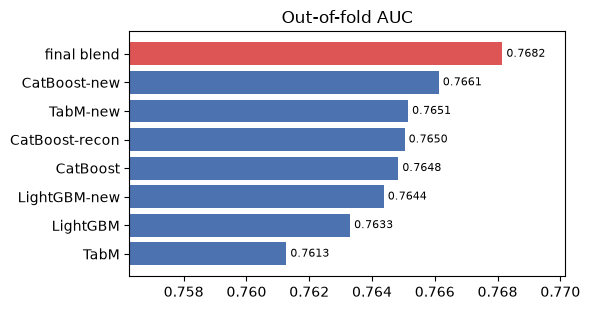

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.2))
show = pd.concat([singles, pd.Series({'final blend': grid.loc[cand, method]})])
ax.barh(show.index, show.values, color=['#4C72B0'] * len(singles) + ['#DD5555'])
ax.set_xlim(show.min() - .005, show.max() + .002)
ax.set_title('Out-of-fold AUC')
for i, v in enumerate(show.values):
    ax.text(v, i, f' {v:.4f}', va='center', fontsize=8)
plt.tight_layout()

## Write the submission

In [5]:
sample = pd.read_csv(DATA / 'sample_submission.csv')
submission = pd.DataFrame({'SK_ID_CURR': test.SK_ID_CURR.astype(int).to_numpy(), 'TARGET': blend_test})
assert list(submission.columns) == list(sample.columns) and len(submission) == len(sample)
assert (submission.SK_ID_CURR.to_numpy() == sample.SK_ID_CURR.to_numpy()).all()
assert np.isfinite(submission.TARGET).all() and submission.TARGET.between(0, 1).all()
submission.to_csv(OUTPUTS / 'submission.csv', index=False)

record = dict(chosen_candidate=cand, method=method, weights=dict(zip(names, map(float, w))),
              nested_oof_auc=float(grid.loc[cand, method]), in_sample_oof_auc=auc(y, blend_oof),
              blend_grid=grid.round(6).to_dict(), single_models=singles.round(6).to_dict(),
              secondary=summary(y, blend_oof))
(OUTPUTS / 'cv_results.json').write_text(json.dumps(record, indent=2))
print(submission.describe().T)

              count           mean           std            min  \
SK_ID_CURR  61500.0  201951.500000  17753.665115  171202.000000   
TARGET      61500.0       0.087753      0.089635       0.001476   

                      25%            50%            75%            max  
SK_ID_CURR  186576.750000  201951.500000  217326.250000  232701.000000  
TARGET           0.028562       0.056559       0.113163       0.770934  
